# Proyecto 2: Diseño generativo de personajes

Luis Gonzalez - 23353  
Jonathan Zacarias - 231104

Universo: habitantes de criptas, cavernas y ruinas en pixel art. Este notebook usa módulos legibles del repositorio. Por defecto inspecciona resultados y regenera la galería; entrenar y evaluar son pasos opcionales. El informe reconoce repetición de arquetipos, inestabilidad y límites para demostrar novedad.

In [1]:
from pathlib import Path
import json, sys, subprocess
import torch
from IPython.display import display, Image
from gan_pipeline import ROOT, RUN, load_json, load_generator, sample
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())
print("Corrida:", RUN)

Python: 3.14.6 PyTorch: 2.13.0+cu130 CUDA: True
Corrida: C:\Users\PC\Desktop\Universidad\Proyecto-2---GAN\runs\paleta_2000


## Datos, licencia y separación

Tiny Dungeon de Kenney y Tiny Creatures de Clint Bellanger/Kenney: CC0. 312 originales; 199 aceptados; 164 train y 35 validación. La revisión elimina escenarios/objetos y una mano aislada. Las familias conocidas y siluetas idénticas/reflejadas permanecen juntas. Solo entrenamiento recibe reflexión; no se permutan colores. `prepare_data.py` reconstruye las decisiones y `dataset/manifest.csv` las registra por archivo.

{
  "raw_count": 312,
  "accepted_count": 199,
  "rejected_count": 113,
  "duplicates_removed": 0,
  "group_count": 128,
  "split_seed": 1729,
  "validation_group_fraction": 0.2,
  "train_count": 164,
  "validation_count": 35,
  "train_groups": 102,
  "validation_groups": 26,
  "augmentation": "original y reflejo horizontal solo en entrenamiento, sin permutar RGB",
  "preprocessing": "negro, centrado de caja no negra en 16x16, NEAREST a 64x64",
  "sources": [
    {
      "name": "Tiny Dungeon",
      "author": "Kenney",
      "license": "CC0",
      "url": "https://kenney.nl/assets/tiny-dungeon"
    },
    {
      "name": "Tiny Creatures",
      "author": "Clint Bellanger, con colaboracion de Kenney",
      "license": "CC0",
      "url": "https://opengameart.org/content/tiny-creatures"
    }
  ],
  "augmented_train_count": 328,
  "manifest_sha256": "f6cbe57bb0b1190ced1fc25594af11469134dd929997ef7e82d9f7cafb671db1"
}


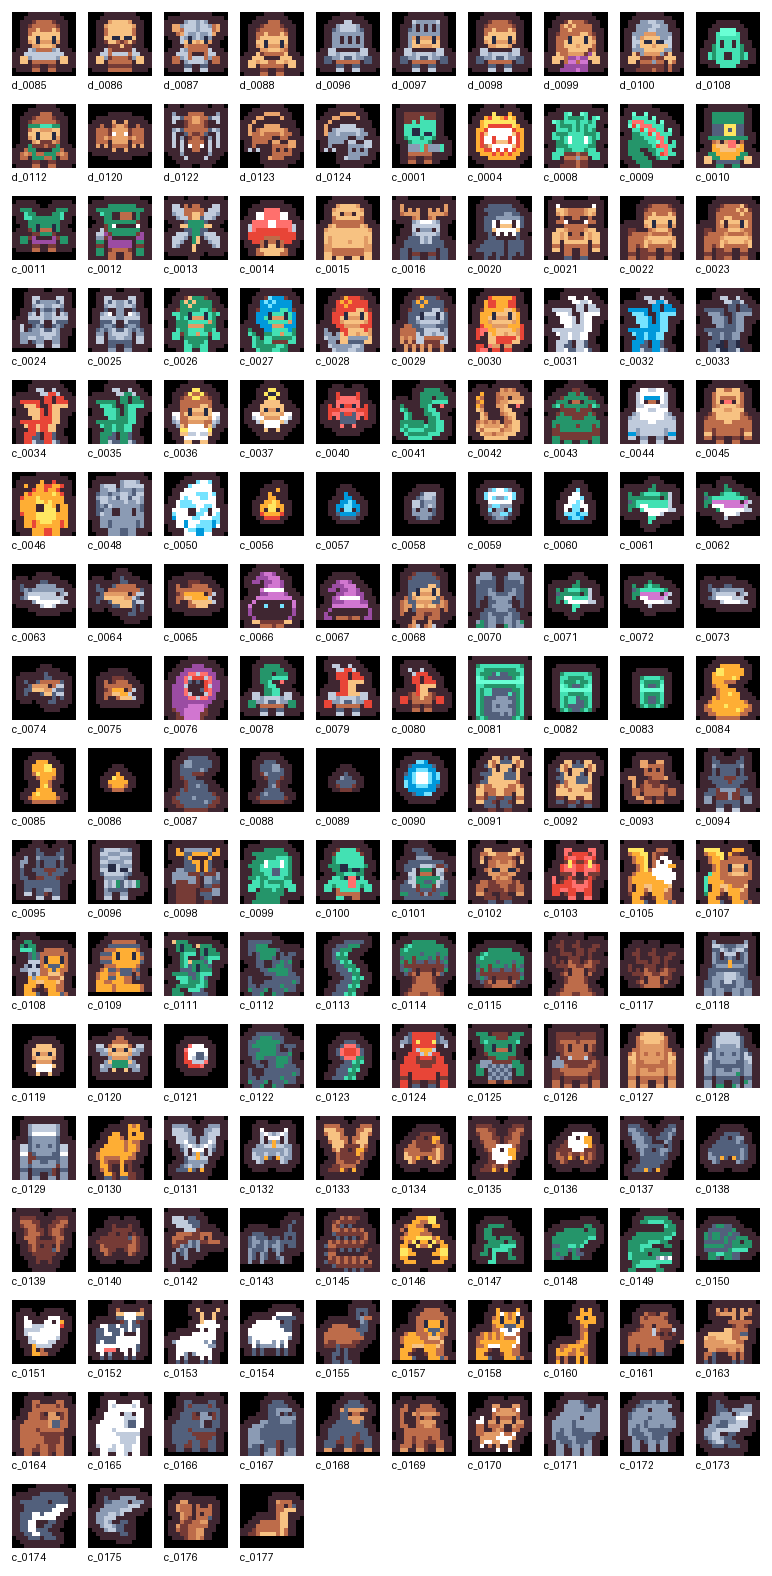

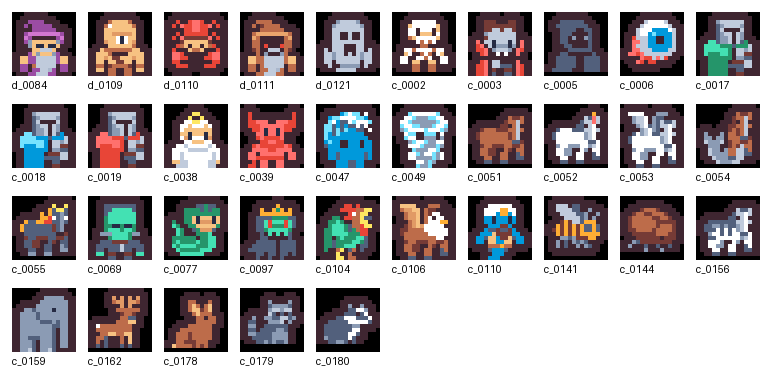

In [2]:
summary=load_json(ROOT/"dataset/summary.json")
print(json.dumps(summary,indent=2,ensure_ascii=False))
display(Image(filename=str(ROOT/"dataset/train_grid.png")))
display(Image(filename=str(ROOT/"dataset/validation_grid.png")))

## Cómo aprende y cómo genera

Durante entrenamiento, D aprende a separar reales y falsas; G recibe a través de D una señal para cambiar sus pesos y hacer más plausibles sus salidas. Cada red tiene su propio Adam. La rejilla aprendida es 16×16, con 23 colores y gradiente sustituto softmax para el argmax. Al generar, G recibe ruido nuevo con los pesos congelados; D no participa y no hay aprendizaje. El diagrama representa ambas etapas.

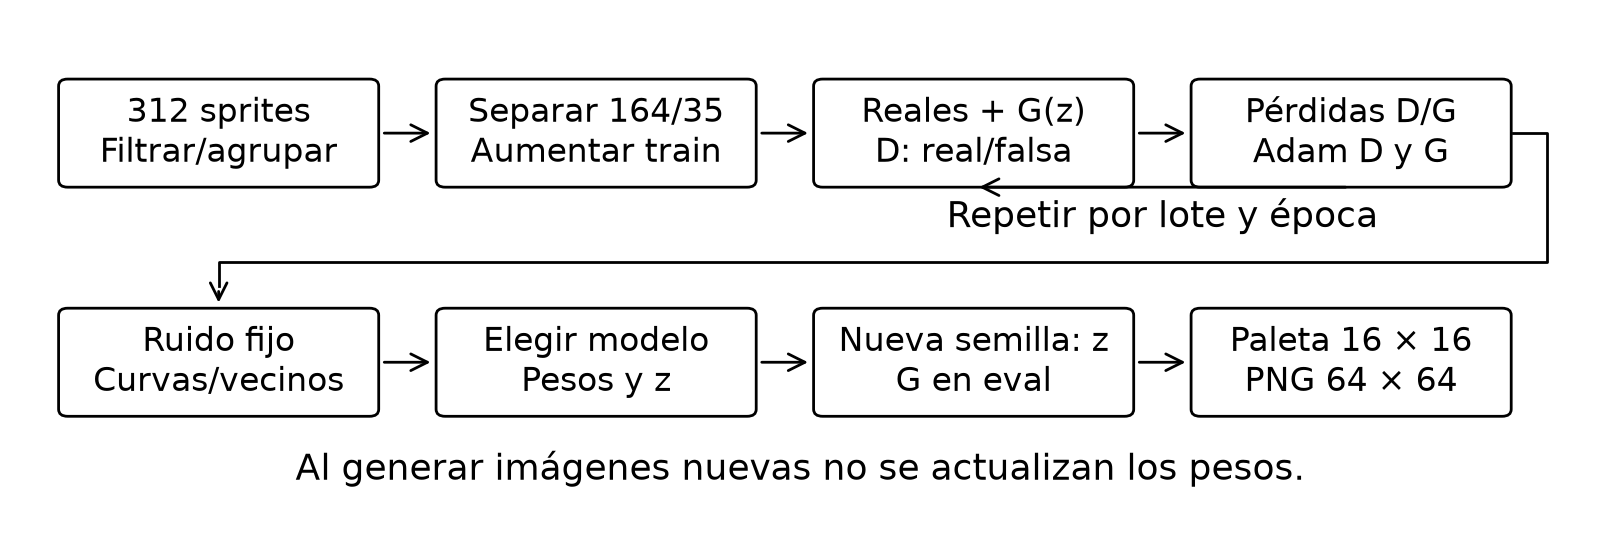

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 23, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): Identity()
  )
)
Parámetros G: 981760


In [3]:
display(Image(filename=str(RUN/"figures/flujo.png")))
manifest=load_json(RUN/"galeria/manifest.json")
model,payload=load_generator(ROOT/manifest["checkpoint"],torch.device("cpu"))
print(model)
print("Parámetros G:",sum(p.numel() for p in model.parameters()))

## Hipótesis previas y controles

Creemos que Hinge mejorará porque usa un margen en D y una pérdida lineal en G. Lo consideraremos útil si preserva diversidad y produce siluetas más claras con el mismo ruido fijo, sin aumentar similitud excesiva con entrenamiento.

Creemos que la normalización espectral mejorará porque limita la amplificación de las convoluciones de D. Lo consideraremos útil si mejora las muestras y evita dominancia prolongada de D. Conservamos BatchNorm.

Estas hipótesis están en `hypothesis.txt`, escrito antes de cada bucle ejecutado, y en `protocolo.md`. Esta versión organizada del notebook reúne esa evidencia. BCE/Hinge cambia solo pérdida; Hinge/SN cambia solo normalización espectral. Las etapas RGB, de paleta y de tasa de D se explican como exploraciones separadas.

In [4]:
for tag in ["base","hinge","hinge_sn"]:
    cfg=load_json(RUN/tag/"config.json")
    print(tag, "loss=",cfg["loss"],"SN=",cfg["spectral_norm"],"épocas=",cfg["epochs"],"tasa D=",cfg.get("learning_rate_D",cfg["learning_rate"]))
    print((RUN/tag/"hypothesis.txt").read_text(encoding="utf-8"))

base loss= bce SN= False épocas= 2000 tasa D= 0.0002
Control: BCE no saturante, BatchNorm y sin normalizacion espectral.
hinge loss= hinge SN= False épocas= 2000 tasa D= 0.0002
Creemos que Hinge mejorara la estabilidad porque utiliza un margen en D y una perdida lineal en G. Lo consideraremos util si preserva diversidad y produce siluetas mas claras con el mismo ruido fijo, sin aumentar similitud excesiva con entrenamiento.
hinge_sn loss= hinge SN= True épocas= 2000 tasa D= 0.0002
Creemos que normalizacion espectral mejorara porque limita la amplificacion de cada convolucion de D. Lo consideraremos util si mejora las muestras y evita dominancia prolongada de D frente al control Hinge. Conservamos BatchNorm y todos los demas factores.


## Repetir entrenamiento desde cero

La ejecución está desactivada por defecto. Cambie `REENTRENAR` a True solo para crear tres corridas nuevas. Los pesos entregados sirven para generar; no reanudan Adam ni D. Las condiciones siguientes conservan todos los controles. La carpeta nueva evita sobrescribir evidencia.

In [5]:
REENTRENAR=False
NUEVA_CORRIDA=ROOT/"runs/reproduccion"
if REENTRENAR:
    for tag in ["base","hinge","hinge_sn"]:
        subprocess.run([sys.executable,"gan_pipeline.py","train","--tag",tag,"--epochs","2000","--run",str(NUEVA_CORRIDA),"--palette","--lr-d","0.0002"],cwd=ROOT,check=True)
else:
    print("Se usan las corridas guardadas; no se vuelve a entrenar.")

Se usan las corridas guardadas; no se vuelve a entrenar.


## Evolución y pérdidas

Los 16 vectores fijos de semilla 123 son iguales entre condiciones y épocas. Una D cerca de cero durante muchas épocas indica separación fácil, no éxito. La diversidad en píxeles puede aumentar por ruido. Las escalas BCE/Hinge no son directamente comparables.

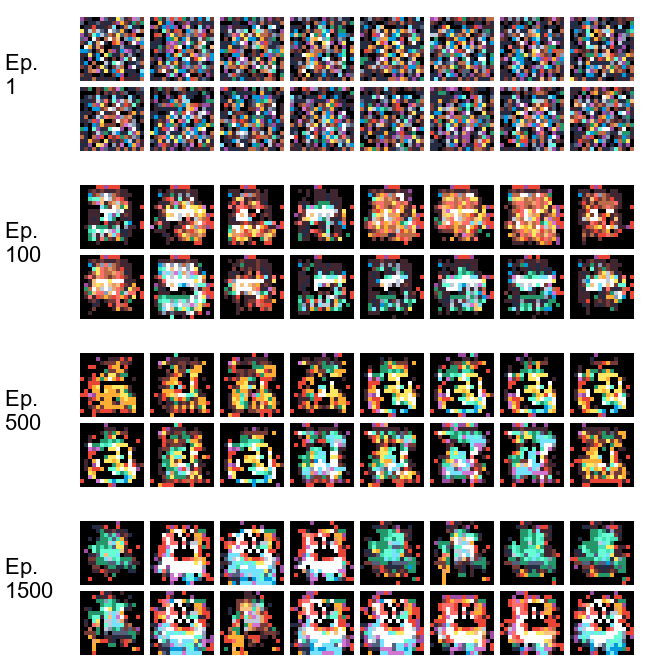

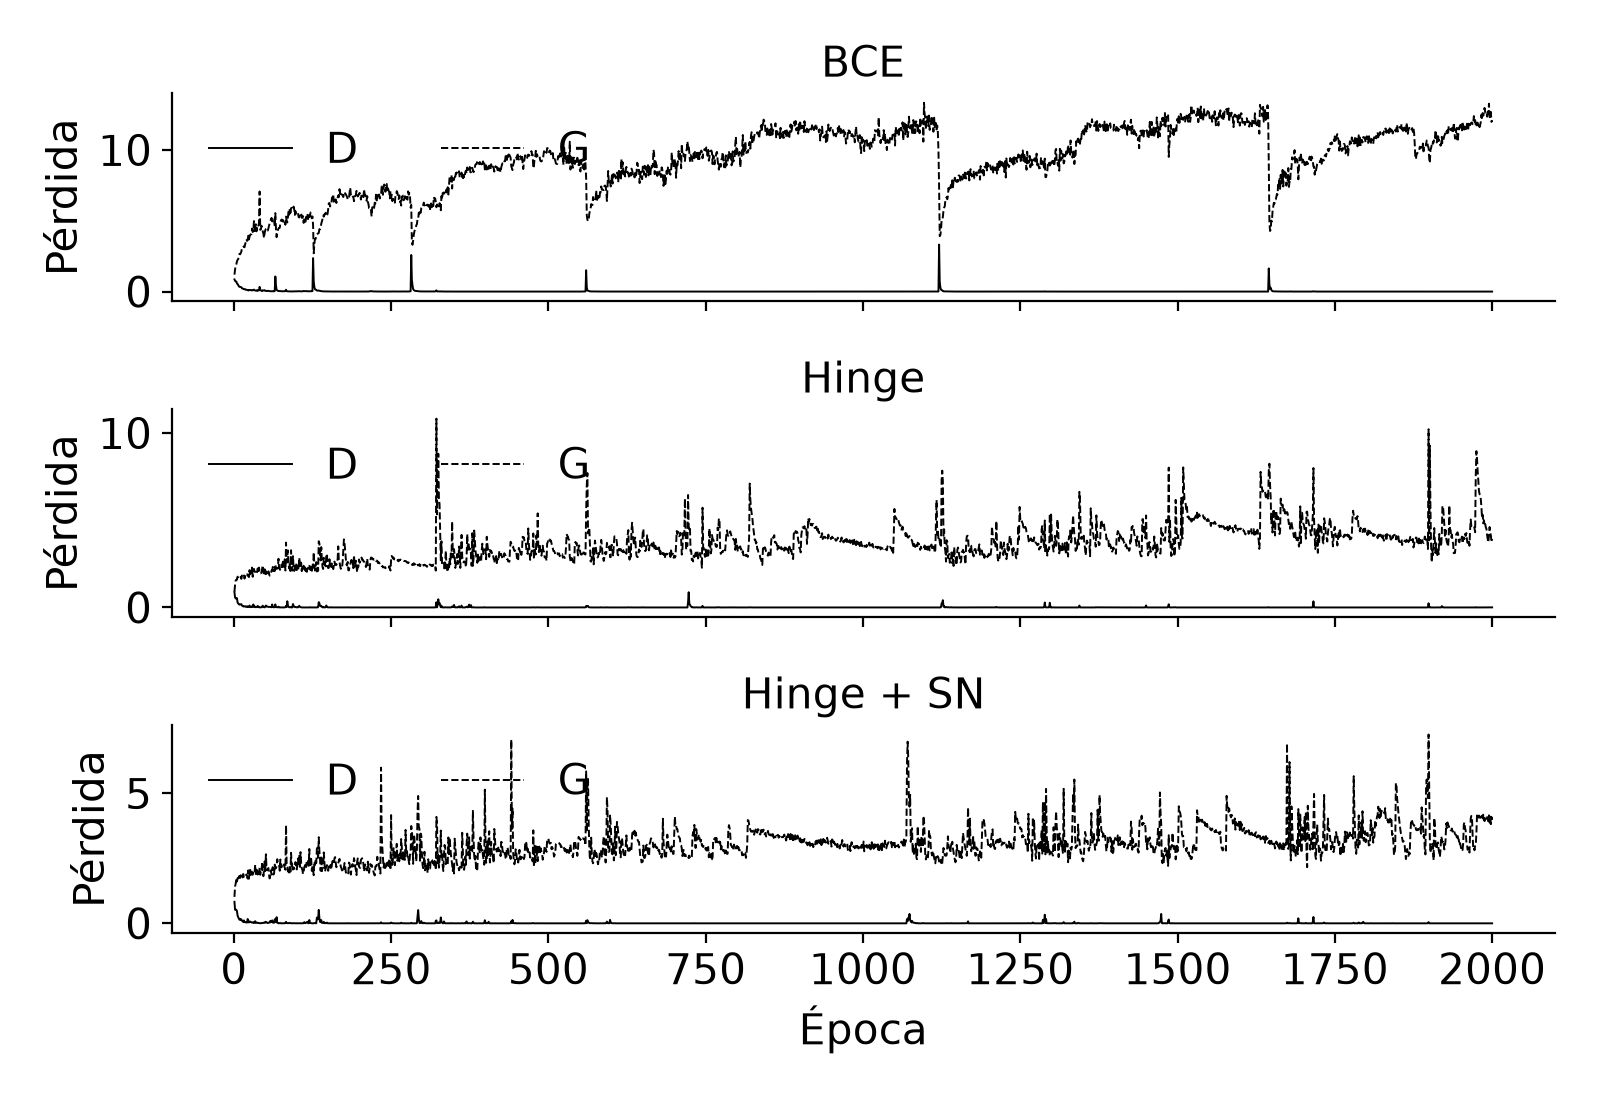

La paleta evita colores intermedios, pero persisten anatomías ambiguas y repetición de arquetipos, compatibles con pérdida parcial de modos. Reducir la tasa de D bajó la diversidad final Hinge a 0.229; reducir sus canales a 16 la bajó a 0.185. Ninguna exploración justificó reemplazar el control. No interpretamos el error bajo de D como éxito.
A época 1500, SN aumenta la diversidad en píxeles de 0.306 a 0.363 frente a Hinge. Sin embargo, varias muestras contienen bloques dispersos y fondos fragmentados. D permanece bajo 0.1 en 1952 de 2000 épocas, frente a 1950 del control. No encontramos evidencia de la mejora de estabilidad prevista; el incremento numérico de diversidad no basta para seleccionar SN.


In [6]:
display(Image(filename=str(RUN/"figures/fixed_evolution_selected.png")))
display(Image(filename=str(RUN/"figures/all_losses.png")))
decision=load_json(RUN/"selection.json")
print(decision["training_conclusion"])
print(decision["stabilization_conclusion"])

## Evaluar y elegir

Evaluamos 200 semillas por condición (1000–1199) con RMS nativo y ResNet-18 preentrenada a 224×224. Los vecinos consideran 328 referencias train incluidas sus reflexiones. Validación no recibe gradientes pero se usa para elegir; no constituye prueba independiente. ResNet se entrenó en fotografías. Una sola semilla experimental y ninguna métrica prueban ausencia de memorización.

base {'diversity': 0.3851250410079956, 'nearest_train_rms_mean': 0.2913137674331665, 'nearest_validation_rms_mean': 0.3093652129173279, 'resnet_cosine_mean': 0.9423974752426147}
hinge {'diversity': 0.3056195080280304, 'nearest_train_rms_mean': 0.3140370845794678, 'nearest_validation_rms_mean': 0.34442979097366333, 'resnet_cosine_mean': 0.9369637966156006}
hinge_sn {'diversity': 0.36337825655937195, 'nearest_train_rms_mean': 0.3276054859161377, 'nearest_validation_rms_mean': 0.352504163980484, 'resnet_cosine_mean': 0.9271714091300964}
Elegimos BCE, checkpoint 1500, por su mayor variedad relativa de siluetas y combinaciones visuales frente a Hinge y SN en las rejillas revisadas. Las tres redes entrenaron 2000 épocas, pero compararlas a 1500 mantiene el mismo punto de evaluación. Es una selección exploratoria: a 2000 BCE perdió diversidad (0.350 frente a 0.385) y no mejoró su legibilidad. La pérdida baja de D no se usó como criterio de éxito.


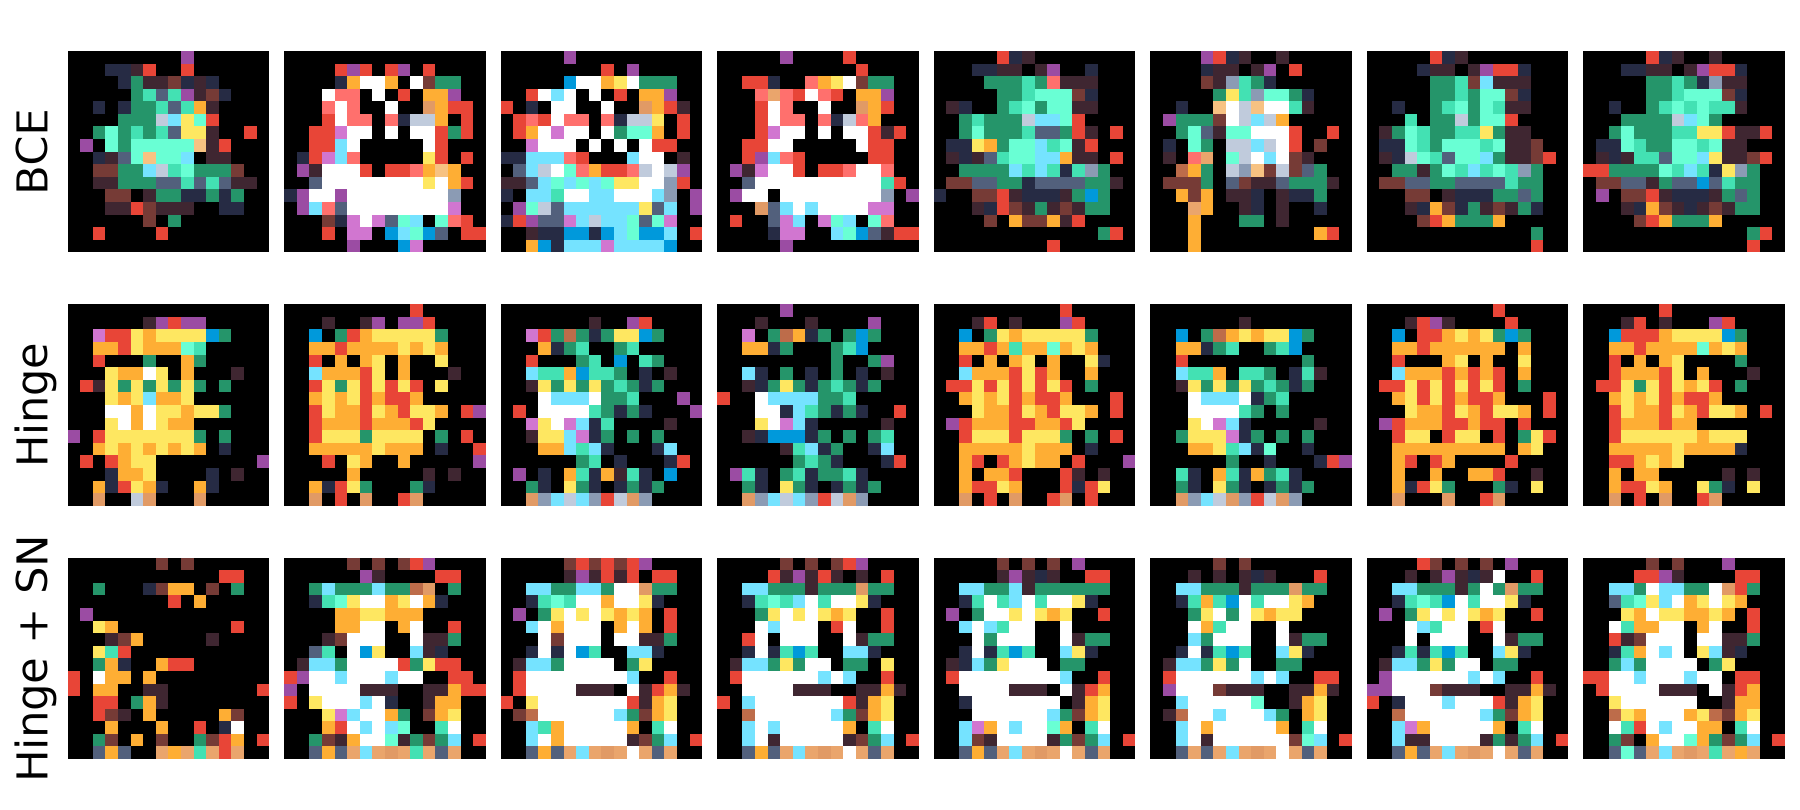

In [7]:
for tag in ["base","hinge","hinge_sn"]:
    metrics=load_json(RUN/tag/"evaluation_epoch_1500.json")
    print(tag,{key:metrics[key] for key in ["diversity","nearest_train_rms_mean","nearest_validation_rms_mean","resnet_cosine_mean"]})
print(decision["model_choice"])
display(Image(filename=str(RUN/"figures/model_comparison.png")))

In [8]:
REEVALUAR=False
if REEVALUAR:
    for tag in ["base","hinge","hinge_sn"]:
        subprocess.run([sys.executable,"gan_pipeline.py","evaluate","--tag",tag,"--epoch","1500","--run",str(RUN),"--cpu"],cwd=ROOT,check=True)

## Galería y vecinos

Diez de 200 candidatos de la condición elegida: 5%. En el desarrollo se evaluaron 2400 candidatos con distintos modelos y checkpoints, repitiendo semillas: 10/2400 = 0.42%. Además se inspeccionaron rejillas fijas. Los nombres y roles son interpretaciones humanas; cada PNG sale del modelo. No consideramos diez semillas distintas como prueba automática de diez personajes semánticamente distintos. La exportación canónica usa CPU y lote 1 para evitar cambios de color del argmax entre dispositivos.

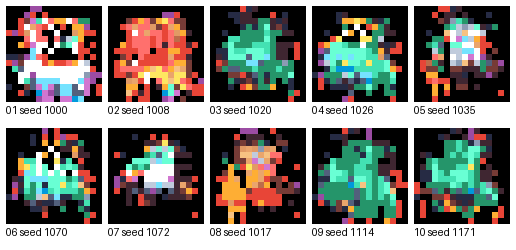

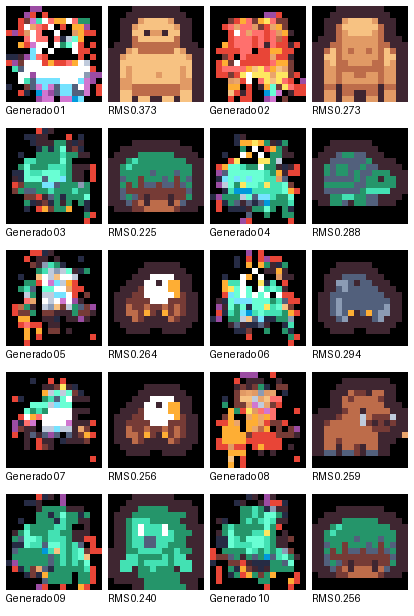

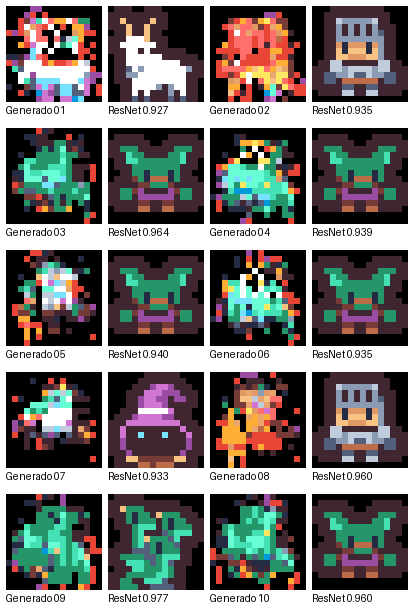

La curación conserva figuras compactas, otras alargadas y algunas con apéndices laterales. Sus colores y proporciones varían, pero varias pertenecen a arquetipos verdes parecidos y la anatomía sigue siendo ambigua. La menor RMS entre los diez es 0.204; esa separación de píxeles no garantiza diez identidades semánticas distintas. Los resultados son conceptos experimentales, no sprites terminados.
Aveline, personaje 09 (seed 1114), fue el más difícil de defender. Su vecino por ResNet es creatures_0111, con coseno 0.977; por RMS es creatures_0099 reflejado, con distancia 0.240. Conserva un cuerpo verde y apéndices que recuerdan formas del dataset. El parecido y la textura compartida impiden afirmar novedad solo con métricas. Este caso sugiere recombinación de colores y siluetas del universo, con detalles todavía poco legibles, y exige más datos y pruebas para defender una identidad nueva.


In [9]:
display(Image(filename=str(RUN/"galeria/galeria_mosaico.png")))
display(Image(filename=str(RUN/"galeria/vecinos_rms.png")))
display(Image(filename=str(RUN/"galeria/vecinos_resnet.png")))
print(decision["gallery_conclusion"])
print(decision["reflection"])

## Regenerar y comprobar

La verificación usa CPU y compara cada PNG y vector guardado con su semilla. La auditoría también comprueba hashes originales, división por grupos, duplicados y controles experimentales.

In [10]:
subprocess.run([sys.executable,"generar.py","--verificar"],cwd=ROOT,check=True)
subprocess.run([sys.executable,"verify_project.py"],cwd=ROOT,check=True)

CompletedProcess(args=['C:\\Users\\PC\\Desktop\\Universidad\\Proyecto-2---GAN\\.venv\\Scripts\\python.exe', 'verify_project.py'], returncode=0)

## Generar imágenes nuevas

Este paso crea una demostración con semillas nuevas, sin entrenar. Los resultados no se filtran; pueden mostrar fallos no presentes en la galería curada.

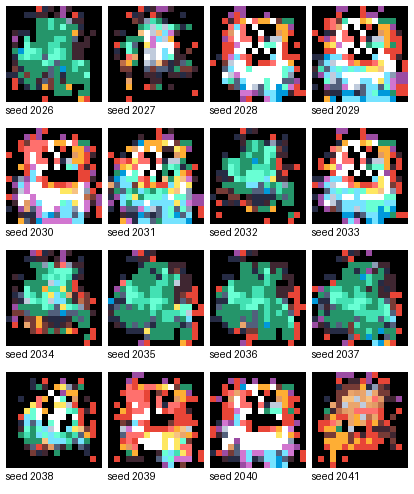

In [11]:
subprocess.run([sys.executable,"generar.py","--seed","2026","--cantidad","16"],cwd=ROOT,check=True)
display(Image(filename=str(ROOT/"output_eval/nuevos/mosaico.png")))

## Referencias y uso de IA

[DCGAN](https://arxiv.org/abs/1511.06434), [GAN](https://arxiv.org/abs/1406.2661), [normalización espectral](https://arxiv.org/abs/1802.05957), [gradientes sustitutos](https://arxiv.org/abs/1308.3432). Codex y ChatGPT ayudaron a revisar código, investigar, depurar datos, ejecutar pruebas y redactar el reporte. Ninguna imagen evaluada proviene de un generador externo. El equipo debe comprender y defender el proceso y sus limitaciones.